# 04. Compare word learners

Owner: rdevasia25. Issue #4. Depends on completed #3.

## Goal

Compare logistic regression, Multinomial Naive Bayes, and a linear SVM with the same word features. Choose settings using training CV, then confirm on the frozen validation set.

## Setup

Logistic regression and SVM learn linear boundaries. Naive Bayes is a simpler word-frequency model; keep it even if it loses.

In [1]:
import json, time, warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from threadpoolctl import threadpool_limits
get_ipython().run_line_magic("run", "./02_split_metrics.ipynb")
NAME = "04_word_comparison"
COMMAND = "uv run --locked jupyter nbconvert --execute --to notebook --inplace notebooks/04_word_comparison.ipynb"
CANDIDATES = ([{"family": "logistic", "C": c} for c in [.25, 1., 4.]] +
              [{"family": "nb", "alpha": a} for a in [.1, .5, 1.]] +
              [{"family": "svm", "C": c} for c in [.25, 1., 4.]])
CONFIG = {"candidates": CANDIDATES,
    "vectorizer": {"analyzer": "word", "ngram_range": [1, 2], "lowercase": True,
                   "min_df": 2, "max_features": 50000, "sublinear_tf": True,
                   "norm": "l2", "dtype": "float32", "stop_words": None,
                   "token_pattern": r"(?u)\b\w\w+\b", "strip_accents": None},
    "logistic": {"solver": "liblinear", "max_iter": 2000, "random_state": 42, "tol": 1e-4},
    "svm": {"dual": "auto", "max_iter": 20000, "random_state": 42, "tol": 1e-4},
    "nb": {"fit_prior": True, "force_alpha": True},
    "cv": {"n_splits": 3, "shuffle": True, "random_state": 42},
    "calibration": {"method": "sigmoid", "ensemble": False, "n_jobs": 1,
                    "cv": "same three stratified training folds; entire pipeline refitted"},
    "selection": "highest mean CV AUROC; first candidate breaks exact ties",
    "handoff": {"tolerance": .002, "preference": ["nb", "logistic", "svm"],
                "reason": "prefer simpler model within tolerance; report measured time too"},
    "bootstrap": {"draws": 2000, "seed": 42, "sampling": "paired class-stratified percentile 95%"},
    "threads": 1,
}
SOURCE_HASH = value_hash(["".join(c["source"]) for c in json.loads((ROOT / "notebooks/04_word_comparison.ipynb").read_text())["cells"]])
CONFIG["notebook_source_sha256"] = SOURCE_HASH
START = time.perf_counter()


## Checks

Verify private inputs and fixed row order using notebook 02. Cross-validation sees only the 8,000 training labels; validation stays outside selection and calibration.

In [2]:
parts = load_partitions()
train, validation = parts["train"], parts["validation"]
folds = list(StratifiedKFold(**CONFIG["cv"]).split(train.text, train.label))
CONFIG["fold_id_sha256"] = [{"fit": value_hash(train.id.iloc[a].tolist()),
                              "score": value_hash(train.id.iloc[b].tolist())} for a, b in folds]
for fit_index, score_index in folds:
    require(not set(fit_index) & set(score_index), "Fold overlap")
    require(len(fit_index) + len(score_index) == 8000, "Fold coverage changed")
# Verify the completed baseline handoff before using it as a paired reference.
baseline_pointer = json.loads((ROOT / "artifacts/03_word_baseline/latest.json").read_text())
require(baseline_pointer["split_sha256"] == parts["split"]["split_sha256"], "Baseline split differs")
for path, expected in baseline_pointer["artifacts"].items():
    require(file_hash(ROOT / path) == expected, "Baseline artifact changed")
baseline_predictions = pd.read_csv(ROOT / baseline_pointer["validation_predictions"], dtype={"id": "string"}, float_precision="round_trip")
baseline_metrics = evaluate_predictions(validation, baseline_predictions)
CONFIG["baseline_prediction_sha256"] = file_hash(ROOT / baseline_pointer["validation_predictions"])
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
private = ROOT / "artifacts" / NAME / run_id
private.mkdir(parents=True, exist_ok=False)


## Method

Refit vocabulary, IDF, and classifier for every candidate and fold. Select the best setting per family and the overall CV leader before validation. For the SVM, fit sigmoid calibration from training-only out-of-fold margins, with the full pipeline inside each calibration fold.

The handoff policy prefers NB, then logistic, then SVM within .002 CV AUROC of the leader. This is a simplicity/cost tradeoff fixed before the run, not a claim that a slightly lower score is equal.

In [3]:
def make_word_model(candidate):
    vector = dict(CONFIG["vectorizer"])
    vector["ngram_range"] = tuple(vector["ngram_range"])
    vector["dtype"] = np.float32
    family = candidate["family"]
    if family == "logistic":
        learner = LogisticRegression(C=candidate["C"], **CONFIG["logistic"])
    elif family == "svm":
        learner = LinearSVC(C=candidate["C"], **CONFIG["svm"])
    else:
        learner = MultinomialNB(alpha=candidate["alpha"], **CONFIG["nb"])
    return Pipeline([("tfidf", TfidfVectorizer(**vector)), ("classifier", learner)])

def ranking_scores(model, texts):
    # AUROC can use margins. Calibration is only needed for the final SVM probabilities.
    if hasattr(model, "decision_function"):
        require(list(model.classes_) == [0, 1], "Unexpected margin orientation")
        return model.decision_function(texts)
    return class1_probabilities(model, texts)

def predictions_for(model, frame):
    return pd.DataFrame({"id": frame.id.to_numpy(), "p_ai": class1_probabilities(model, frame.text)})

def paired_interval(truth, reference, treatment):
    aligned = truth[["id", "label"]].merge(reference.rename(columns={"p_ai": "reference"}), on="id", validate="one_to_one")
    aligned = aligned.merge(treatment.rename(columns={"p_ai": "treatment"}), on="id", validate="one_to_one")
    require(len(aligned) == len(truth), "Bootstrap ID coverage changed")
    y, ref, arm = (aligned[k].to_numpy() for k in ["label", "reference", "treatment"])
    groups = [np.flatnonzero(y == label) for label in [0, 1]]
    rng = np.random.default_rng(CONFIG["bootstrap"]["seed"])
    differences = []
    for _ in range(CONFIG["bootstrap"]["draws"]):
        idx = np.concatenate([rng.choice(g, len(g), replace=True) for g in groups])
        differences.append(roc_auc_score(y[idx], arm[idx]) - roc_auc_score(y[idx], ref[idx]))
    low, high = np.quantile(differences, [.025, .975])
    return {"delta_auroc": float(roc_auc_score(y, arm) - roc_auc_score(y, ref)),
            "ci_low": float(low), "ci_high": float(high)}


## Run

Search first and save the selection before evaluating validation. Record every candidate, including failures. A convergence warning makes that candidate fail.

In [4]:
artifacts = []
try:
    search_start = time.perf_counter()
    cv_rows = []
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        for index, candidate in enumerate(CANDIDATES):
            candidate_start = time.perf_counter()
            scores, fold_seconds = [], []
            oof = np.full(len(train), np.nan)
            error = None
            try:
                for fit_idx, score_idx in folds:
                    fold_start = time.perf_counter()
                    model = make_word_model(candidate)
                    model.fit(train.text.iloc[fit_idx], train.label.iloc[fit_idx])
                    values = ranking_scores(model, train.text.iloc[score_idx])
                    require(np.isfinite(values).all(), "Invalid OOF scores")
                    oof[score_idx] = values
                    scores.append(float(roc_auc_score(train.label.iloc[score_idx], values)))
                    fold_seconds.append(time.perf_counter() - fold_start)
            except Exception as exc:
                error = type(exc).__name__
            row = {"index": index, **candidate, "status": "failed" if error else "completed",
                   "error_type": error, "fold_auroc": scores, "fold_seconds": fold_seconds,
                   "cv_mean": float(np.mean(scores)) if not error else None,
                   "cv_std": float(np.std(scores)) if not error else None,
                   "search_seconds": time.perf_counter() - candidate_start}
            cv_rows.append(row)
            oof_path = private / f"candidate_{index}_oof.csv"
            pd.DataFrame({"id": train.id, "score": oof}).to_csv(oof_path, index=False)
            artifacts.append(oof_path)
    search_seconds = time.perf_counter() - search_start
    complete = [row for row in cv_rows if row["status"] == "completed"]
    require(bool(complete), "No successful candidate")
    leader = max(complete, key=lambda row: row["cv_mean"])
    winners = {family: max([row for row in complete if row["family"] == family], key=lambda row: row["cv_mean"])
               for family in ["logistic", "nb", "svm"]}
    eligible = [family for family in CONFIG["handoff"]["preference"]
                if winners[family]["cv_mean"] >= leader["cv_mean"] - .002]
    handoff_family = eligible[0]
    selection = {"cv_leader": leader, "family_winners": winners,
                 "handoff_family": handoff_family, "candidates": cv_rows,
                 "config": CONFIG, "split_sha256": parts["split"]["split_sha256"],
                 "validation_inspected": False, "utc": datetime.now(timezone.utc).isoformat()}
    selection_path = ROOT / "results" / NAME / f"{run_id}-selection.json"
    save_new_json(selection_path, selection)
    artifacts.append(selection_path)
    models, family_predictions, fit_rows, saved_models = {}, {}, [], {}
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        for family, winner in winners.items():
            candidate = CANDIDATES[winner["index"]]
            model = make_word_model(candidate)
            if family == "svm":
                model = CalibratedClassifierCV(model, cv=folds, **{k: v for k, v in CONFIG["calibration"].items() if k != "cv"})
            fit_start = time.perf_counter()
            model.fit(train.text, train.label)
            fit_seconds = time.perf_counter() - fit_start
            evaluation_start = time.perf_counter()
            train_pred, valid_pred = predictions_for(model, train), predictions_for(model, validation)
            tm, vm = evaluate_predictions(train, train_pred), evaluate_predictions(validation, valid_pred)
            evaluate_seconds = time.perf_counter() - evaluation_start
            model_path = private / f"{family}.joblib"
            train_path, valid_path = private / f"{family}_train.csv", private / f"{family}_validation.csv"
            joblib.dump(model, model_path)
            train_pred.to_csv(train_path, index=False); valid_pred.to_csv(valid_path, index=False)
            restored = joblib.load(model_path)
            reload_diff = float(np.max(np.abs(class1_probabilities(restored, validation.text) - valid_pred.p_ai.to_numpy())))
            require(reload_diff <= 1e-12, "Reload changed probabilities")
            artifacts.extend([model_path, train_path, valid_path])
            saved_models[family] = {"model": str(model_path.relative_to(ROOT)),
                "train_predictions": str(train_path.relative_to(ROOT)),
                "validation_predictions": str(valid_path.relative_to(ROOT)), "candidate": candidate,
                "cv_mean": winner["cv_mean"]}
            models[family], family_predictions[family] = model, valid_pred
            fit_rows.append({"family": family, "train_auroc": tm["auroc"], "validation_auroc": vm["auroc"],
                "validation_accuracy_at_0_5": vm["accuracy_at_0_5"], "fit_seconds": fit_seconds,
                "evaluation_seconds": evaluate_seconds, "max_reload_difference": reload_diff,
                "cv_mean": winner["cv_mean"], "cv_std": winner["cv_std"]})
    bootstrap_start = time.perf_counter()
    comparisons = [{"family": family, "reference": "baseline_C1", **paired_interval(validation, baseline_predictions, pred)}
                   for family, pred in family_predictions.items()]
    bootstrap_seconds = time.perf_counter() - bootstrap_start
except Exception as exc:
    record_run(NAME, COMMAND, CONFIG, SEED, len(train), len(validation),
               {"validation_auroc": None, "candidate_results": locals().get("cv_rows", [])},
               time.perf_counter() - START, status="failed", error_type=type(exc).__name__)
    raise RuntimeError("Word comparison failed; see safe record.") from None


## Results

Fold variation is over three training folds, not independent repeated datasets. The bootstrap conditions on the fitted models and reused validation rows; it does not cover training variability or selection bias. SVM probabilities use sigmoid calibration, without a claim of perfect calibration.

,index,family,C,status,error_type,fold_auroc,fold_seconds,cv_mean,cv_std,search_seconds,alpha
0,0,logistic,0.25,completed,None,"[0.9069126352052782, 0.9078304058773314, 0.924...","[2.1910519170342013, 2.051887583977077, 2.0418...",0.913188,0.008234,6.284875,NaN
1,1,logistic,1.00,completed,None,"[0.925960875526228, 0.9244233847067465, 0.9347...","[2.3467919590184465, 2.1622712920070626, 2.562...",0.928375,0.004545,7.071352,NaN
2,2,logistic,4.00,completed,None,"[0.9349541283371818, 0.9331506414834594, 0.940...","[2.611646000004839, 2.2632675420027226, 2.6017...",0.936100,0.002987,7.476694,NaN
3,3,nb,NaN,completed,None,"[0.879932314412936, 0.8930127959276175, 0.9038...","[2.2393726669833995, 2.3236605420242995, 2.034...",0.892278,0.009794,6.597843,0.1
4,4,nb,NaN,completed,None,"[0.8757466728001342, 0.8912295540151904, 0.909...","[2.1986527910339646, 2.384132542007137, 2.3015...",0.892106,0.013729,6.884753,0.5
5,5,nb,NaN,completed,None,"[0.8720373496672519, 0.8886179565880974, 0.910...","[2.180247167008929, 2.174169041973073, 1.93503...",0.890456,0.015843,6.289601,1.0
6,6,svm,0.25,completed,None,"[0.9344637508702514, 0.9321001539740259, 0.939...","[2.173005082993768, 2.1065661250031553, 2.0492...",0.935429,0.003186,6.328847,NaN
7,7,svm,1.00,completed,None,"[0.9368610893353023, 0.9350581648410603, 0.939...","[2.1842192920157686, 1.9857748330105096, 2.165...",0.937294,0.002025,6.335348,NaN
8,8,svm,4.00,completed,None,"[0.9340031784557832, 0.93325748978474, 0.93606...","[1.9934798749745823, 2.0314023749670014, 2.101...",0.934441,0.001186,6.126568,NaN


,family,train_auroc,validation_auroc,validation_accuracy_at_0_5,fit_seconds,evaluation_seconds,max_reload_difference,cv_mean,cv_std
0,logistic,0.999925,0.941252,0.8780,2.784756,1.326397,0.0,0.936100,0.002987
1,nb,0.990249,0.903867,0.8270,2.442242,1.564219,0.0,0.892278,0.009794
2,svm,1.000000,0.943079,0.8755,9.568155,1.570904,0.0,0.937294,0.002025


,family,reference,delta_auroc,ci_low,ci_high
0,logistic,baseline_C1,0.008524,0.006423,0.010789
1,nb,baseline_C1,-0.028861,-0.037640,-0.020338
2,svm,baseline_C1,0.010351,0.006338,0.014584


Training-CV leader: candidate 7; handoff family: logistic
Search: 59.539s; bootstrap: 11.161s


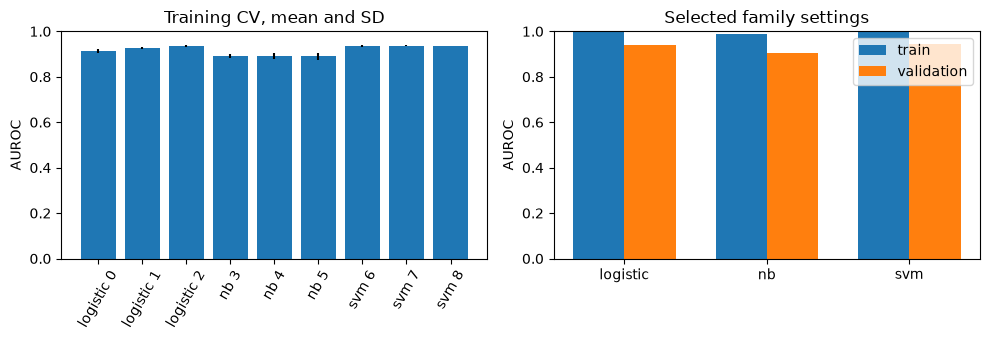

In [5]:
display(pd.DataFrame(cv_rows))
display(pd.DataFrame(fit_rows))
display(pd.DataFrame(comparisons))
print(f"Training-CV leader: candidate {leader['index']}; handoff family: {handoff_family}")
print(f"Search: {search_seconds:.3f}s; bootstrap: {bootstrap_seconds:.3f}s")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
labels = [f"{row['family']} {row['index']}" for row in complete]
axes[0].bar(labels, [row["cv_mean"] for row in complete], yerr=[row["cv_std"] for row in complete])
axes[0].tick_params(axis="x", rotation=60)
axes[0].set(title="Training CV, mean and SD", ylabel="AUROC", ylim=(0, 1))
for partition, offset in [("train", -.18), ("validation", .18)]:
    axes[1].bar(np.arange(3) + offset, [r[f"{partition}_auroc"] for r in fit_rows], width=.36, label=partition)
axes[1].set(xticks=np.arange(3), xticklabels=[r["family"] for r in fit_rows], ylim=(0, 1), title="Selected family settings", ylabel="AUROC")
axes[1].legend()
fig.tight_layout()
plot_path = private / "comparison.png"
fig.savefig(plot_path, dpi=140)
artifacts.append(plot_path)
plt.show()


## Takeaway

- Tried all nine fixed candidates, with a fresh feature fit in every fold.
- The tables keep every arm and show the CV choice, validation confirmation, cost, and paired uncertainty.
- Next: compare character features in #5 and one-pass self-training in #7. No validation-based retuning.

## Save

Commit safe aggregate records and notebook plots. Keep OOF scores, fitted models, and row predictions ignored. The stable private pointer exposes the selected logistic setting for #7 and the handoff model for #5.

In [6]:
metrics = {"validation_auroc": next(row["validation_auroc"] for row in fit_rows if row["family"] == handoff_family),
    "candidate_results": cv_rows, "family_results": fit_rows, "paired_vs_baseline": comparisons,
    "cv_leader_index": leader["index"], "handoff_family": handoff_family,
    "search_seconds": search_seconds, "bootstrap_seconds": bootstrap_seconds}
CONFIG["extra_versions"] = {name: importlib.metadata.version(name) for name in ["joblib", "matplotlib", "threadpoolctl"]}
record_path = record_run(NAME, COMMAND, CONFIG, SEED, len(train), len(validation), metrics,
                         time.perf_counter() - START, artifacts=artifacts)
pointer = {"result": str(record_path.relative_to(ROOT)), "result_sha256": file_hash(record_path),
    "selection": str(selection_path.relative_to(ROOT)), "split_sha256": parts["split"]["split_sha256"],
    "handoff_family": handoff_family, "models": saved_models,
    "artifacts": {str(p.relative_to(ROOT)): file_hash(p) for p in artifacts}}
pointer_path = ROOT / "artifacts" / NAME / "latest.json"
temporary = pointer_path.with_suffix(".tmp")
temporary.write_text(json.dumps(pointer, indent=2, sort_keys=True) + "\n")
temporary.replace(pointer_path)
print("Saved all candidate results, measured comparisons, and private handoff.")


Saved all candidate results, measured comparisons, and private handoff.
